In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
import os

Saving sepeda.jfif to sepeda.jfif
Nama gambar: sepeda.jfif
Tinggi: 1308
Lebar: 736


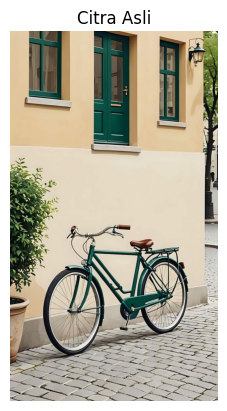

In [3]:
uploaded = files.upload()

nama_file = list(uploaded.keys())[0]

img = cv2.imread(nama_file)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

tinggi, lebar = img.shape[:2]

print("Nama gambar:", nama_file)
print("Tinggi:", tinggi)
print("Lebar:", lebar)

plt.imshow(img)
plt.title("Citra Asli")
plt.axis("off")
plt.show()

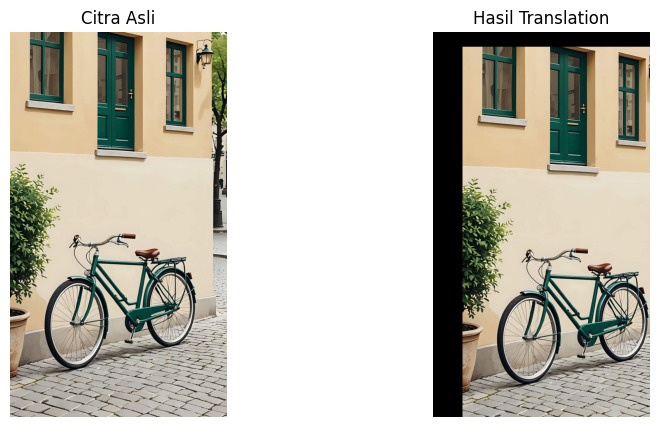

In [4]:
# TRANSFORMASI TRANSLATION

M = np.float32([
    [1, 0, 100],
    [0, 1, 50]
])

translation = cv2.warpAffine(
    img, M, (lebar, tinggi)
)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Citra Asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(translation)
plt.title("Hasil Translation")
plt.axis("off")

plt.show()

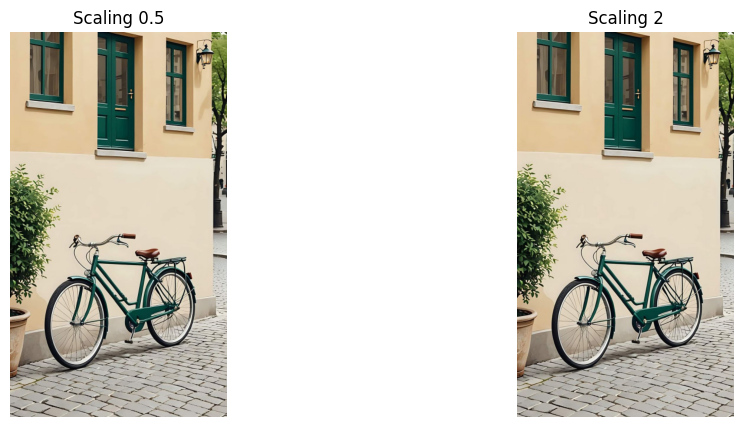

In [5]:
# TRANSFORMASI SCALING

scaling_05 = cv2.resize(
    img, None, fx=0.5, fy=0.5
)

scaling_2 = cv2.resize(
    img, None, fx=2, fy=2
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(scaling_05)
plt.title("Scaling 0.5")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(scaling_2)
plt.title("Scaling 2")
plt.axis("off")

plt.show()

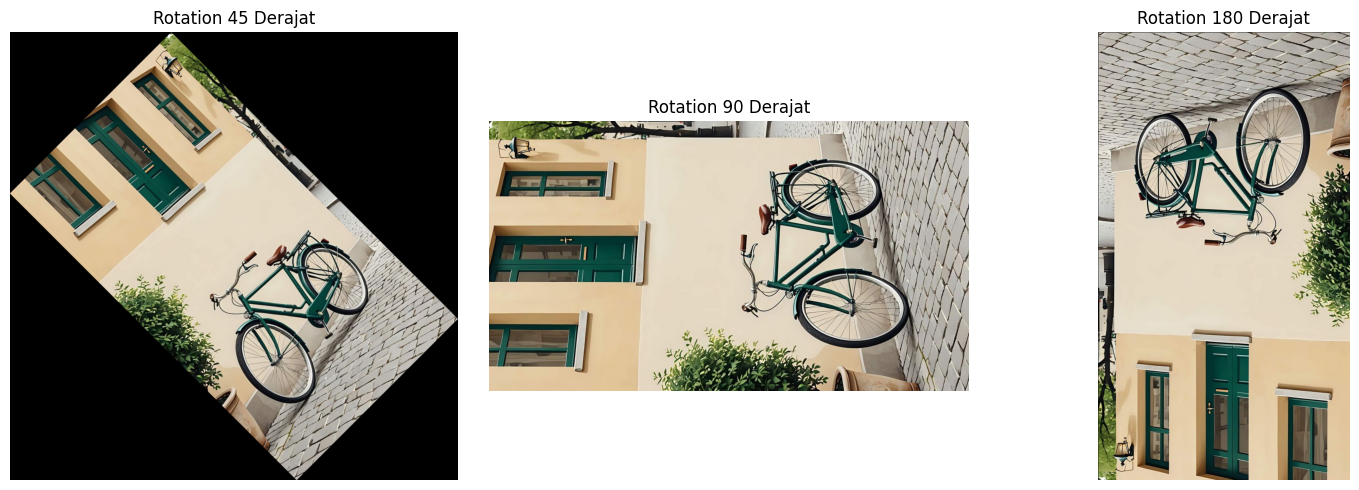

In [6]:
# TRANSFORMASI ROTATION

def rotasi(gambar, sudut):
    tinggi, lebar = gambar.shape[:2]

    pusat = (lebar // 2, tinggi // 2)

    M = cv2.getRotationMatrix2D(
        pusat, sudut, 1.0
    )

    cos = abs(M[0, 0])
    sin = abs(M[0, 1])

    lebar_baru = int(
        (tinggi * sin) + (lebar * cos)
    )

    tinggi_baru = int(
        (tinggi * cos) + (lebar * sin)
    )

    M[0, 2] += (lebar_baru / 2) - pusat[0]
    M[1, 2] += (tinggi_baru / 2) - pusat[1]

    return cv2.warpAffine(
        gambar, M, (lebar_baru, tinggi_baru)
    )

rotation_45 = rotasi(img, 45)
rotation_90 = rotasi(img, 90)
rotation_180 = rotasi(img, 180)

# MENAMPILKAN HASIL ROTATION

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(rotation_45)
plt.title("Rotation 45 Derajat")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(rotation_90)
plt.title("Rotation 90 Derajat")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(rotation_180)
plt.title("Rotation 180 Derajat")
plt.axis("off")

plt.tight_layout()
plt.show()

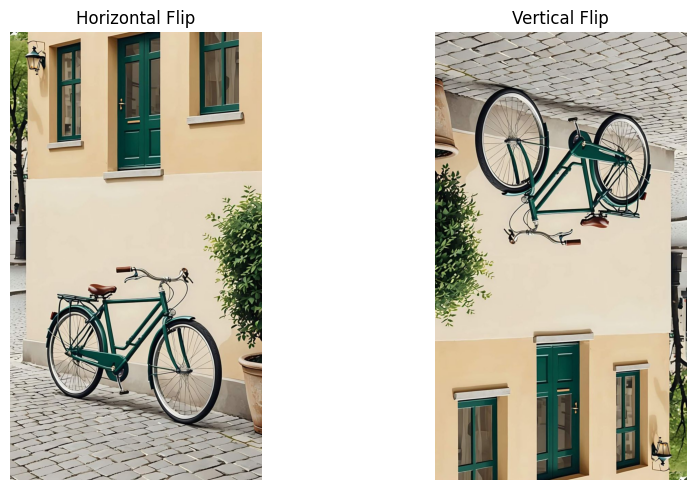

In [7]:
# TRANSFORMASI FLIP

horizontal_flip = cv2.flip(img, 1)
vertical_flip = cv2.flip(img, 0)

# MENAMPILKAN HASIL FLIP

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(horizontal_flip)
plt.title("Horizontal Flip")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(vertical_flip)
plt.title("Vertical Flip")
plt.axis("off")

plt.tight_layout()
plt.show()

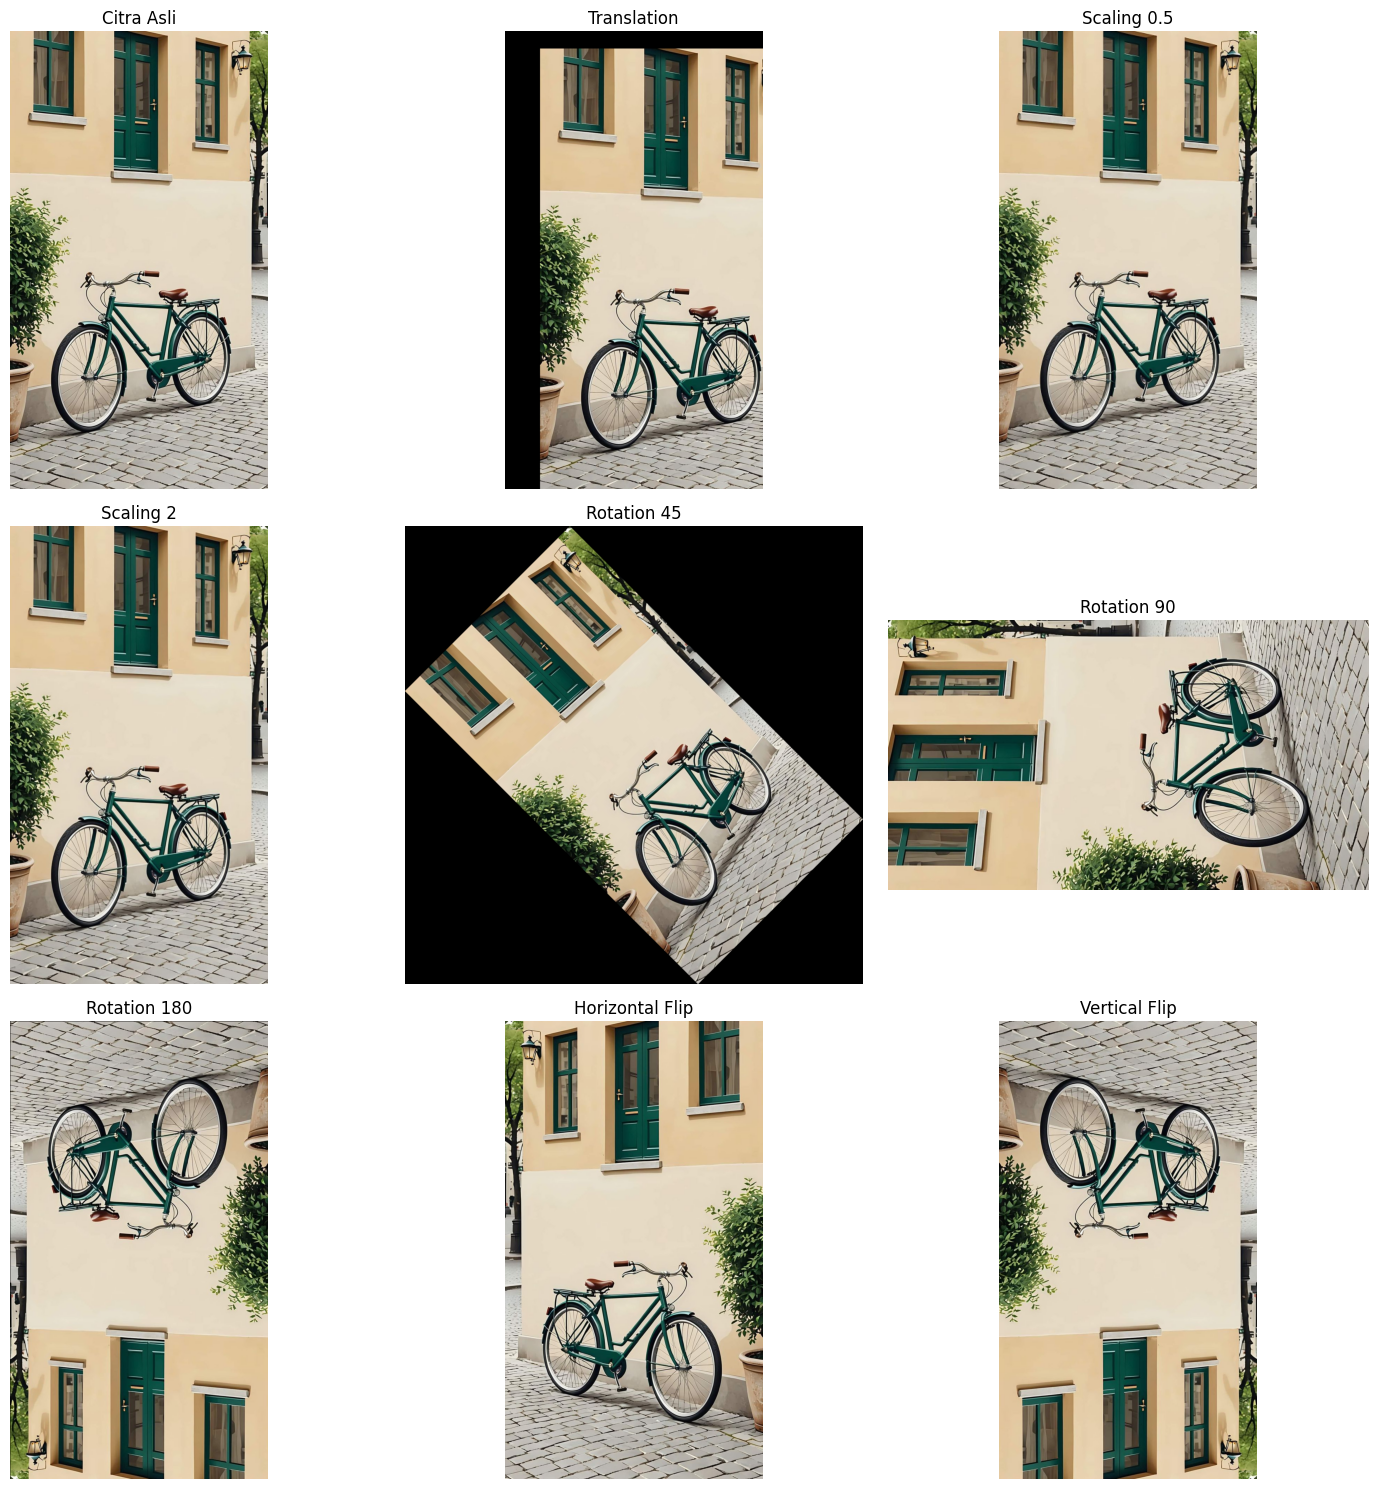

In [8]:
# MENAMPILKAN SEMUA HASIL TRANSFORMASI

hasil = [
    ("Citra Asli", img),
    ("Translation", translation),
    ("Scaling 0.5", scaling_05),
    ("Scaling 2", scaling_2),
    ("Rotation 45", rotation_45),
    ("Rotation 90", rotation_90),
    ("Rotation 180", rotation_180),
    ("Horizontal Flip", horizontal_flip),
    ("Vertical Flip", vertical_flip)
]

plt.figure(figsize=(15, 15))

for i, (judul, gambar) in enumerate(hasil):
    plt.subplot(3, 3, i + 1)
    plt.imshow(gambar)
    plt.title(judul)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
# MENYIMPAN HASIL TRANSFORMASI

import os

folder = "hasil_transformasi"
os.makedirs(folder, exist_ok=True)

for judul, gambar in hasil:
    nama = judul.lower().replace(" ", "_") + ".png"
    lokasi = os.path.join(folder, nama)

    gambar_bgr = cv2.cvtColor(
        gambar, cv2.COLOR_RGB2BGR
    )

    cv2.imwrite(lokasi, gambar_bgr)

print("Semua hasil berhasil disimpan!")

Semua hasil berhasil disimpan!
